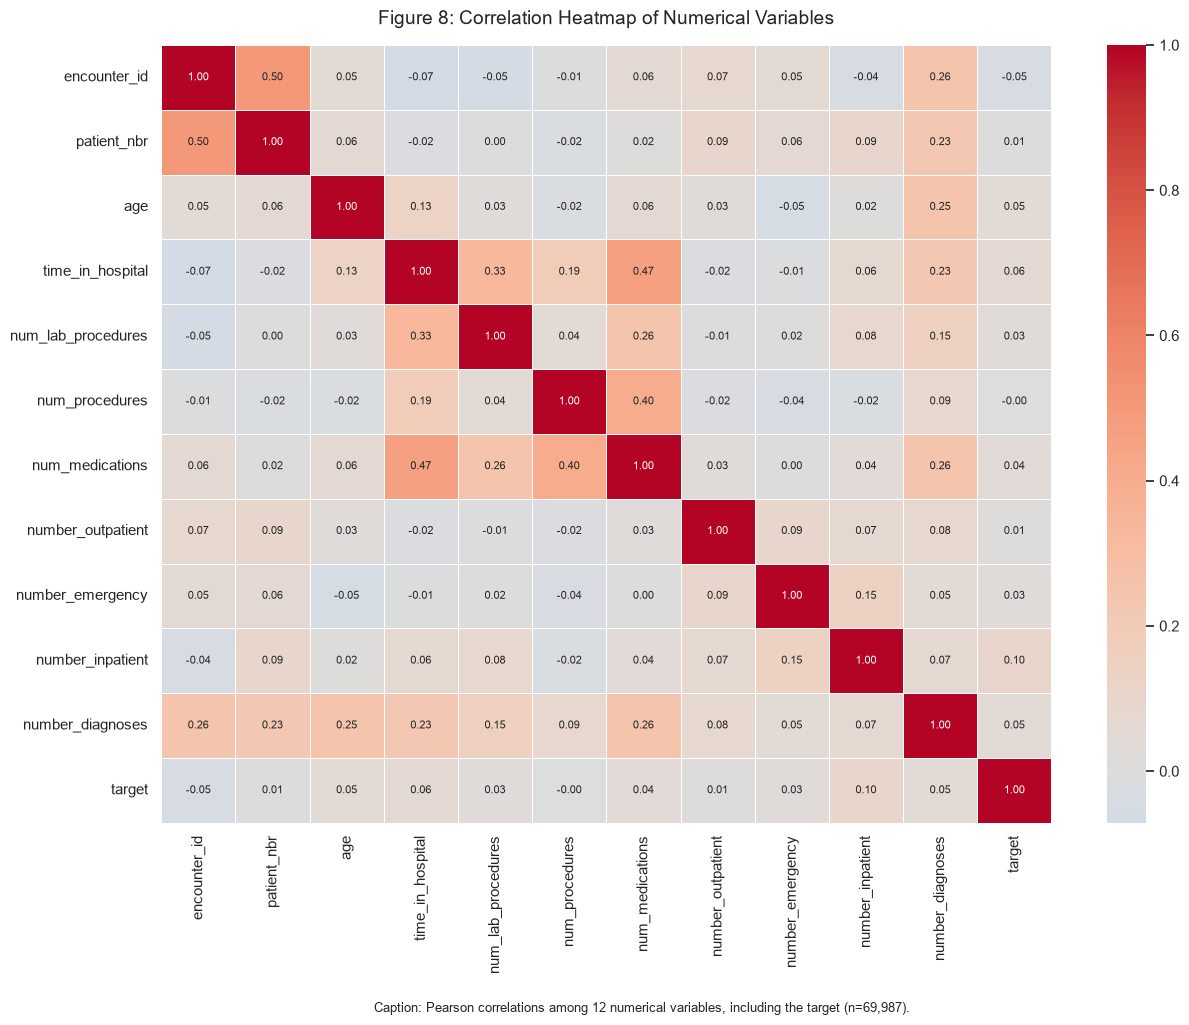

In [9]:
# Figure 8: Correlation Heatmap

numeric_columns = df.select_dtypes(include=["int64", "float64"]).columns

correlation_matrix = df[numeric_columns].corr()

plt.figure(figsize=(13, 10))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    linewidths=0.5,
    annot_kws={"size": 8}
)

plt.title(
    "Figure 8: Correlation Heatmap of Numerical Variables",
    fontsize=14,
    pad=15
)

plt.figtext(
    0.5, -0.02,
    f"Caption: Pearson correlations among {len(numeric_columns)} "
    f"numerical variables, including the target (n={len(df):,}).",
    ha="center",
    fontsize=9
)

plt.tight_layout()

plt.savefig(
    "../reports/figures/fig08_correlation_heatmap.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

## 11. Figure 8 – Correlation Heatmap

Correlation analysis is used to examine the strength and direction of relationships between numerical variables.

The Pearson correlation coefficient ranges from -1 to +1:

- +1 indicates a strong positive linear relationship.
- -1 indicates a strong negative linear relationship.
- 0 indicates little or no linear relationship.

The heatmap includes numerical variables and the target variable to explore potential relationships with 30-day readmission.

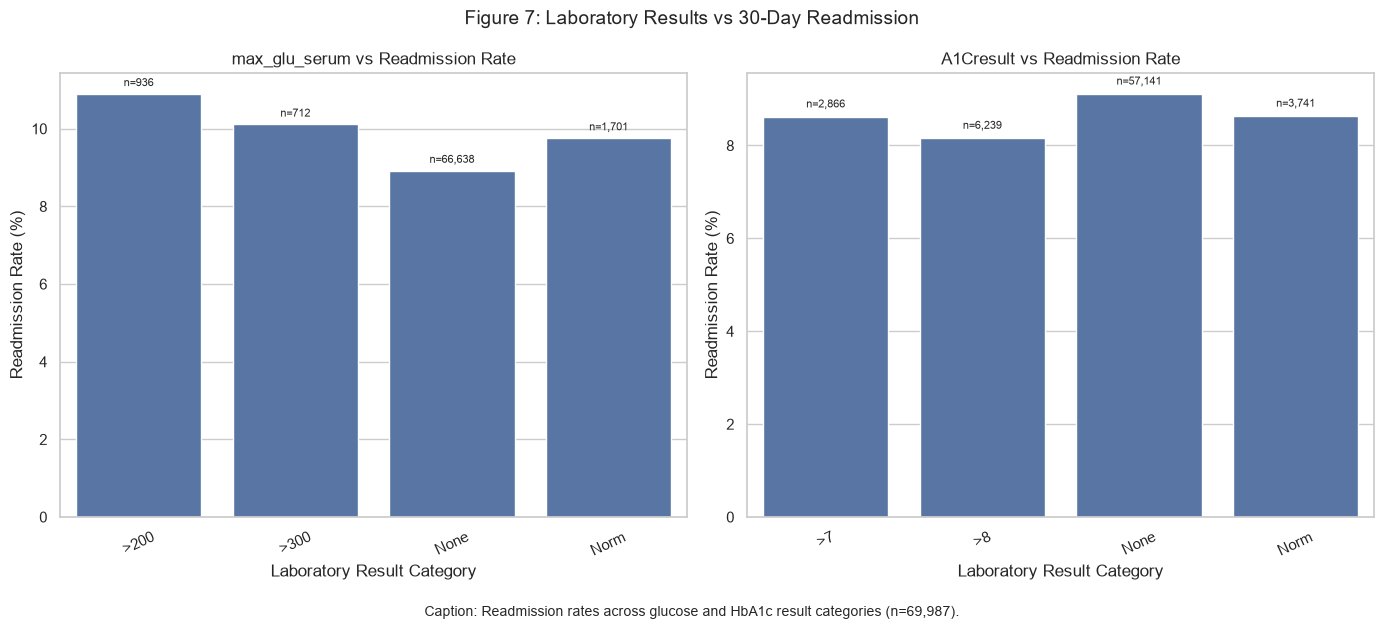

In [8]:
# Figure 7: Laboratory Results vs Readmission

lab_features = ["max_glu_serum", "A1Cresult"]

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

for ax, column in zip(axes, lab_features):

    lab_analysis = (
        df.groupby(column, observed=True)
        .agg(
            total_patients=("target", "count"),
            readmitted=("target", "sum"),
            readmission_rate=("target", "mean")
        )
        .reset_index()
    )

    lab_analysis["readmission_rate"] *= 100

    sns.barplot(
        data=lab_analysis,
        x=column,
        y="readmission_rate",
        ax=ax
    )

    ax.set_title(f"{column} vs Readmission Rate")
    ax.set_xlabel("Laboratory Result Category")
    ax.set_ylabel("Readmission Rate (%)")
    ax.tick_params(axis="x", rotation=25)

    for i, row in lab_analysis.reset_index(drop=True).iterrows():
        ax.text(
            i,
            row["readmission_rate"] + 0.2,
            f'n={row["total_patients"]:,}',
            ha="center",
            fontsize=8
        )

fig.suptitle(
    "Figure 7: Laboratory Results vs 30-Day Readmission",
    fontsize=14
)

fig.text(
    0.5, -0.03,
    f"Caption: Readmission rates across glucose and HbA1c result "
    f"categories (n={len(df):,}).",
    ha="center",
    fontsize=10
)

plt.tight_layout()

plt.savefig(
    "../reports/figures/fig07_lab_readmission.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

## 10. Figure 7 – Laboratory Results vs Readmission

This analysis examines the relationship between maximum glucose serum results, HbA1c results and 30-day hospital readmission.

The readmission rate is calculated for each laboratory result category to identify possible patterns.

Total missing values: 0
Columns with missing values: 0


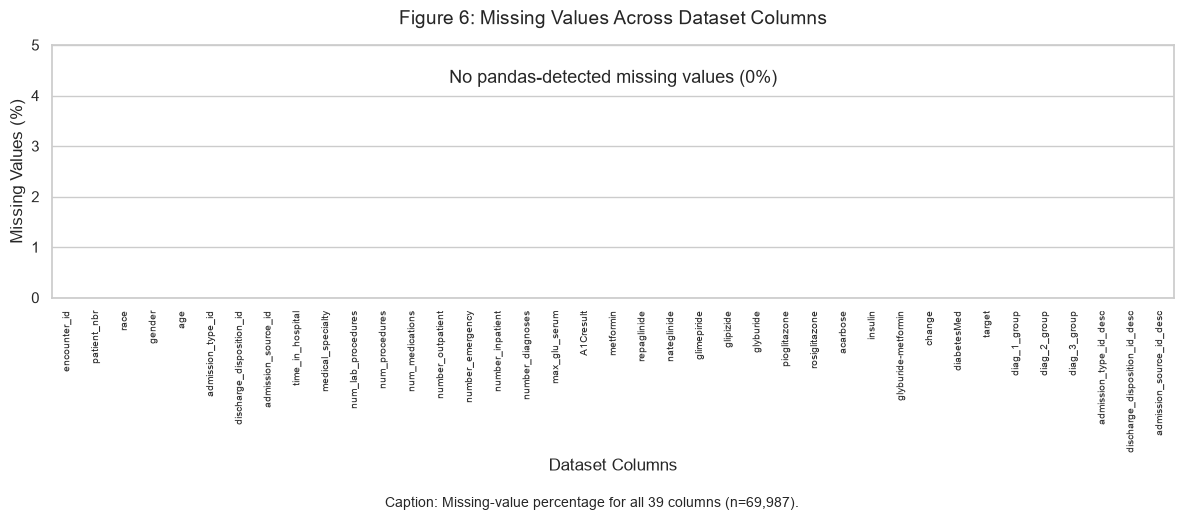

,Missing_Count,Missing_Percentage
encounter_id,0,0.0
patient_nbr,0,0.0
race,0,0.0
gender,0,0.0
age,0,0.0
admission_type_id,0,0.0
discharge_disposition_id,0,0.0
admission_source_id,0,0.0
time_in_hospital,0,0.0
medical_specialty,0,0.0


In [7]:
# Figure 6: Missing-Value Analysis

missing_count = df.isna().sum()
missing_percentage = df.isna().mean() * 100

missing_analysis = pd.DataFrame({
    "Missing_Count": missing_count,
    "Missing_Percentage": missing_percentage
})

print("Total missing values:", missing_count.sum())
print("Columns with missing values:", (missing_count > 0).sum())

plt.figure(figsize=(12, 5))

ax = sns.barplot(
    x=missing_analysis.index,
    y=missing_analysis["Missing_Percentage"]
)

plt.title("Figure 6: Missing Values Across Dataset Columns",
          fontsize=14, pad=15)
plt.xlabel("Dataset Columns")
plt.ylabel("Missing Values (%)")

plt.xticks(rotation=90, fontsize=7)
plt.ylim(0, 5)

plt.text(
    0.5, 0.85,
    "No pandas-detected missing values (0%)",
    transform=ax.transAxes,
    ha="center",
    fontsize=13
)

plt.figtext(
    0.5, -0.03,
    f"Caption: Missing-value percentage for all {len(df.columns)} "
    f"columns (n={len(df):,}).",
    ha="center",
    fontsize=10
)

plt.tight_layout()

plt.savefig(
    "../reports/figures/fig06_missing_values.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

display(missing_analysis)

## 9. Figure 6 – Missing-Value Analysis

This analysis examines the completeness of the processed dataset.

The number and percentage of pandas-detected missing values are calculated for every column.

The purpose is to verify data completeness before further analysis and model development.

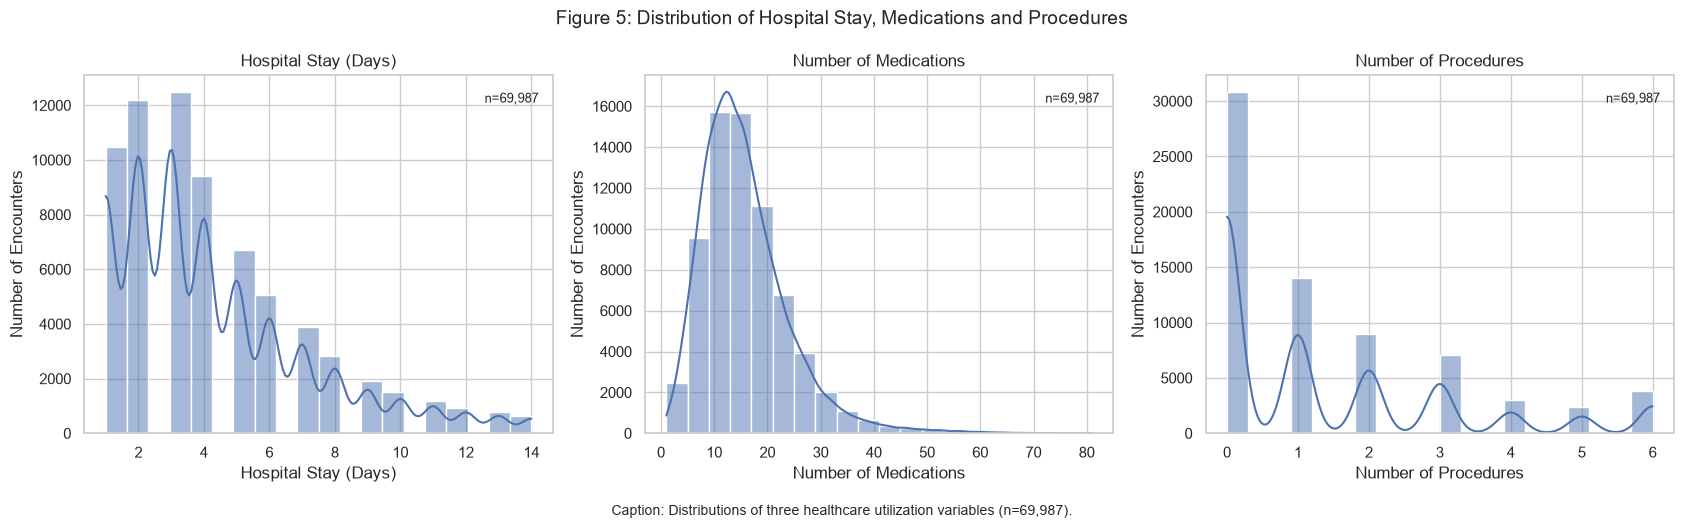

In [6]:
# Figure 5: Distributions of Hospital Stay, Medications and Procedures

features = [
    ("time_in_hospital", "Hospital Stay (Days)"),
    ("num_medications", "Number of Medications"),
    ("num_procedures", "Number of Procedures")
]

fig, axes = plt.subplots(1, 3, figsize=(17, 5))

for ax, (column, label) in zip(axes, features):
    sns.histplot(
        data=df,
        x=column,
        bins=20,
        kde=True,
        ax=ax
    )

    ax.set_title(label)
    ax.set_xlabel(label)
    ax.set_ylabel("Number of Encounters")

    ax.text(
        0.97, 0.95,
        f"n={df[column].count():,}",
        transform=ax.transAxes,
        ha="right",
        va="top",
        fontsize=9
    )

fig.suptitle(
    "Figure 5: Distribution of Hospital Stay, Medications and Procedures",
    fontsize=14
)

fig.text(
    0.5, -0.03,
    f"Caption: Distributions of three healthcare utilization variables "
    f"(n={len(df):,}).",
    ha="center",
    fontsize=10
)

plt.tight_layout()

plt.savefig(
    "../reports/figures/fig05_feature_distributions.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

## 8. Figure 5 – Distribution of Hospital Stay, Medications and Procedures

This analysis examines the distributions of hospital stay duration, medication usage and medical procedures.

The three variables help describe the treatment intensity and healthcare resource utilization during hospital encounters.

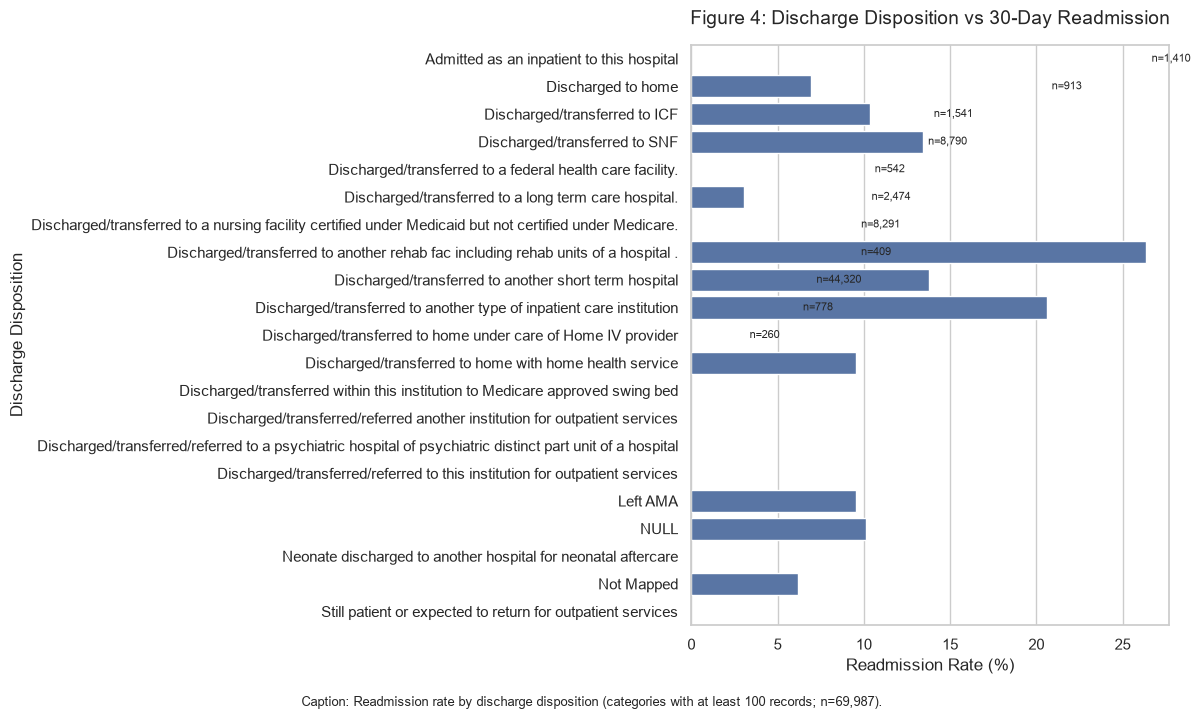

,discharge_disposition_id_desc,total_patients,readmitted,readmission_rate
0,Admitted as an inpatient to this hospital,9,2,22.222222
1,Discharged to home,44320,3079,6.947202
2,Discharged/transferred to ICF,542,56,10.332103
3,Discharged/transferred to SNF,8790,1180,13.424346
4,Discharged/transferred to a federal health car...,3,0,0.000000
5,Discharged/transferred to a long term care hos...,260,8,3.076923
6,Discharged/transferred to a nursing facility c...,25,1,4.000000
7,Discharged/transferred to another rehab fac in...,1410,372,26.382979
8,Discharged/transferred to another short term h...,1541,212,13.757300
9,Discharged/transferred to another type of inpa...,913,188,20.591457


In [5]:
# Figure 4: Discharge Disposition vs Readmission

discharge_analysis = (
    df.groupby("discharge_disposition_id_desc", observed=True)
    .agg(
        total_patients=("target", "count"),
        readmitted=("target", "sum"),
        readmission_rate=("target", "mean")
    )
    .reset_index()
)

discharge_analysis["readmission_rate"] *= 100

# Keep categories with at least 100 records
plot_data = discharge_analysis[
    discharge_analysis["total_patients"] >= 100
].sort_values("readmission_rate", ascending=False)

plt.figure(figsize=(12, 7))

ax = sns.barplot(
    data=plot_data,
    x="readmission_rate",
    y="discharge_disposition_id_desc"
)

plt.title("Figure 4: Discharge Disposition vs 30-Day Readmission",
          fontsize=14, pad=15)
plt.xlabel("Readmission Rate (%)")
plt.ylabel("Discharge Disposition")

for i, row in enumerate(plot_data.itertuples()):
    ax.text(
        row.readmission_rate + 0.3,
        i,
        f'n={row.total_patients:,}',
        va="center",
        fontsize=8
    )

plt.figtext(
    0.5, -0.02,
    f"Caption: Readmission rate by discharge disposition "
    f"(categories with at least 100 records; n={len(df):,}).",
    ha="center",
    fontsize=9
)

plt.tight_layout()

plt.savefig(
    "../reports/figures/fig04_discharge_readmission.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

display(discharge_analysis)

## 7. Figure 4 – Discharge Disposition vs Readmission

This analysis examines the relationship between hospital discharge disposition and 30-day readmission.

Discharge disposition describes the patient's destination or status when leaving the hospital.

The analysis focuses on categories with sufficient observations to provide more reliable comparisons.

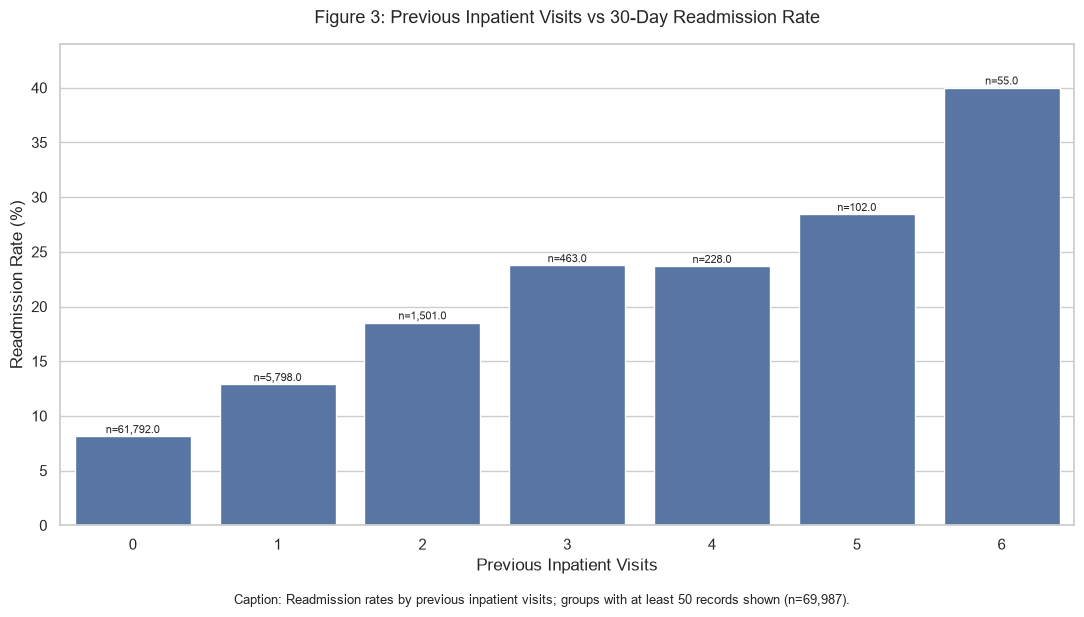

,number_inpatient,total_patients,readmitted,readmission_rate
0,0,61792,5023,8.128884
1,1,5798,747,12.883753
2,2,1501,278,18.520986
3,3,463,110,23.758099
4,4,228,54,23.684211
5,5,102,29,28.431373
6,6,55,22,40.000000
7,7,19,9,47.368421
8,8,13,3,23.076923
9,9,7,3,42.857143


In [4]:
# Figure 3: Previous Inpatient Visits vs Readmission

inpatient_analysis = (
    df.groupby("number_inpatient", observed=True)
    .agg(
        total_patients=("target", "count"),
        readmitted=("target", "sum"),
        readmission_rate=("target", "mean")
    )
    .reset_index()
)

inpatient_analysis["readmission_rate"] *= 100

# Limit the visualization to values with sufficient observations
plot_data = inpatient_analysis[
    inpatient_analysis["total_patients"] >= 50
].copy()

plt.figure(figsize=(11, 6))

ax = sns.barplot(
    data=plot_data,
    x="number_inpatient",
    y="readmission_rate"
)

plt.title(
    "Figure 3: Previous Inpatient Visits vs 30-Day Readmission Rate",
    fontsize=13,
    pad=15
)
plt.xlabel("Previous Inpatient Visits")
plt.ylabel("Readmission Rate (%)")

for i, row in plot_data.reset_index(drop=True).iterrows():
    ax.text(
        i,
        row["readmission_rate"] + 0.3,
        f'n={row["total_patients"]:,}',
        ha="center",
        fontsize=8
    )

plt.ylim(0, plot_data["readmission_rate"].max() + 4)

plt.figtext(
    0.5, -0.02,
    f"Caption: Readmission rates by previous inpatient visits; "
    f"groups with at least 50 records shown (n={len(df):,}).",
    ha="center",
    fontsize=9
)

plt.tight_layout()

plt.savefig(
    "../reports/figures/fig03_inpatient_readmission.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

display(inpatient_analysis)

## 6. Figure 3 – Previous Inpatient Visits vs Readmission

This analysis investigates the relationship between the number of inpatient visits in the year before the current encounter and 30-day readmission.

It helps identify whether previous hospitalization patterns are associated with future readmission risk.

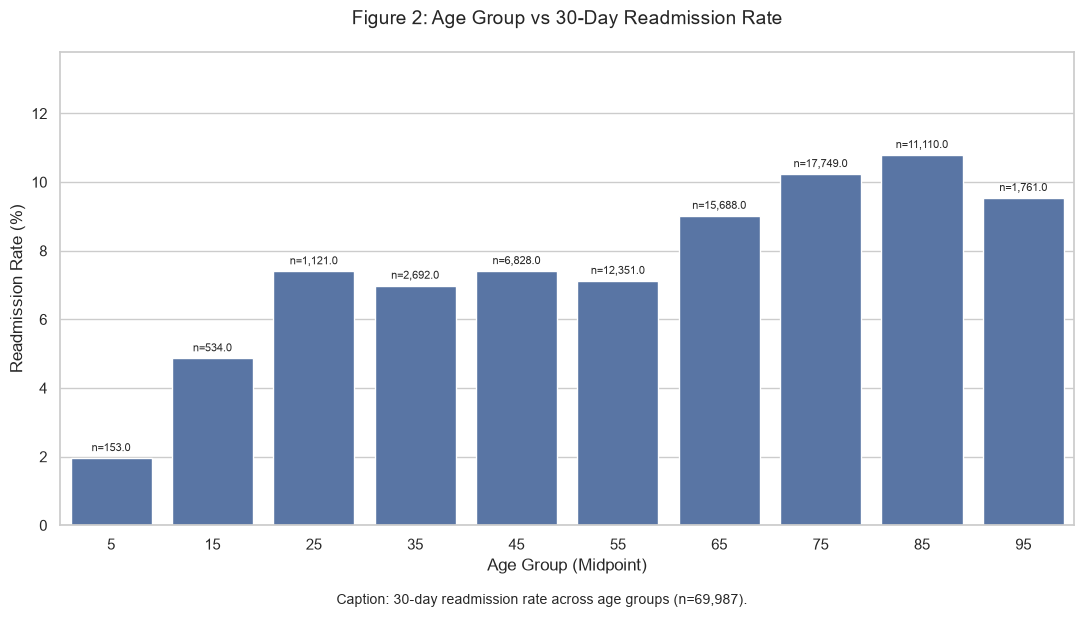

,age,total_patients,readmitted,readmission_rate
0,5,153,3,1.960784
1,15,534,26,4.868914
2,25,1121,83,7.404103
3,35,2692,188,6.983655
4,45,6828,506,7.410662
5,55,12351,880,7.124929
6,65,15688,1415,9.019633
7,75,17749,1817,10.237196
8,85,11110,1199,10.792079
9,95,1761,168,9.540034


In [3]:
# Figure 2: Age vs Readmission Rate

age_analysis = (
    df.groupby("age", observed=True)
    .agg(
        total_patients=("target", "count"),
        readmitted=("target", "sum"),
        readmission_rate=("target", "mean")
    )
    .reset_index()
)

age_analysis["readmission_rate"] *= 100

plt.figure(figsize=(11, 6))

ax = sns.barplot(
    data=age_analysis,
    x="age",
    y="readmission_rate"
)

plt.title("Figure 2: Age Group vs 30-Day Readmission Rate",
          fontsize=14, pad=20)
plt.xlabel("Age Group (Midpoint)")
plt.ylabel("Readmission Rate (%)")

# Display sample size above each bar
for i, row in age_analysis.iterrows():
    ax.text(
        i,
        row["readmission_rate"] + 0.2,
        f'n={row["total_patients"]:,}',
        ha="center",
        fontsize=8
    )

plt.ylim(0, age_analysis["readmission_rate"].max() + 3)

plt.figtext(
    0.5, -0.02,
    f"Caption: 30-day readmission rate across age groups (n={len(df):,}).",
    ha="center",
    fontsize=10
)

plt.tight_layout()

plt.savefig(
    "../reports/figures/fig02_age_readmission.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

display(age_analysis)

## 5. Figure 2 – Age vs Readmission Rate

This analysis examines the relationship between patient age and 30-day hospital readmission.

The original age ranges were converted into numerical midpoint values during data cleaning.

The readmission rate is calculated as the percentage of patients in each age group whose target value is 1.

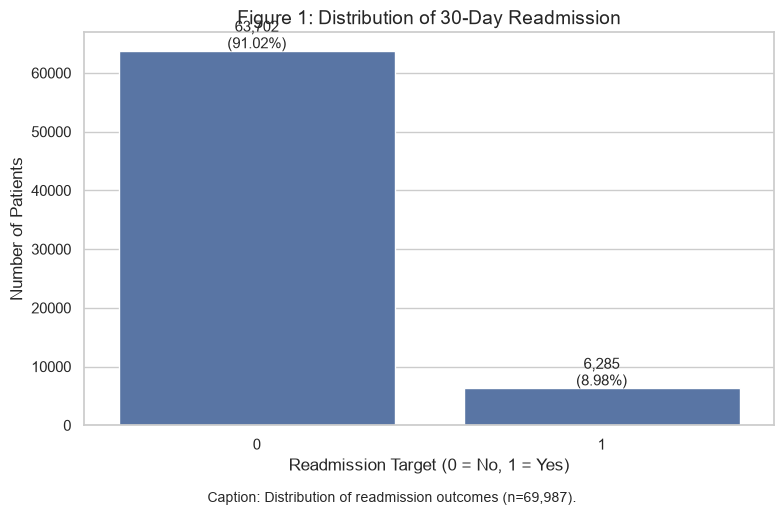

In [2]:
# Figure 1: Target Class Distribution

target_counts = df["target"].value_counts().sort_index()

plt.figure(figsize=(8, 5))

ax = sns.barplot(
    x=target_counts.index.astype(str),
    y=target_counts.values
)

plt.title("Figure 1: Distribution of 30-Day Readmission", fontsize=14)
plt.xlabel("Readmission Target (0 = No, 1 = Yes)")
plt.ylabel("Number of Patients")

# Display count and percentage
total = len(df)

for i, count in enumerate(target_counts.values):
    percentage = count / total * 100
    ax.text(i, count + 500, f"{count:,}\n({percentage:.2f}%)",
            ha="center", fontsize=11)

plt.figtext(
    0.5, -0.02,
    f"Caption: Distribution of readmission outcomes (n={total:,}).",
    ha="center", fontsize=10
)

plt.tight_layout()

# Save figure
Path("../reports/figures").mkdir(parents=True, exist_ok=True)

plt.savefig(
    "../reports/figures/fig01_target_balance.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

## 4. Figure 1 – Target Class Distribution

The target variable represents whether a patient was readmitted within 30 days.

- 1: Readmitted within 30 days.
- 0: Not readmitted within 30 days.

This visualization helps identify class imbalance in the dataset.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

sns.set_theme(style="whitegrid")

# Load processed dataset
DATA_PATH = Path("../data/processed/cohort_v1.parquet")

df = pd.read_parquet(DATA_PATH)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Dataset shape: (69987, 39)


,encounter_id,patient_nbr,race,gender,age,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,medical_specialty,...,glyburide-metformin,change,diabetesMed,target,diag_1_group,diag_2_group,diag_3_group,admission_type_id_desc,discharge_disposition_id_desc,admission_source_id_desc
0,12522,48330783,Caucasian,Female,85,2,1,4,13,Unknown,...,No,Ch,Yes,0,Circulatory,Circulatory,Other,Urgent,Discharged to home,Transfer from a hospital
1,15738,63555939,Caucasian,Female,95,3,3,4,12,InternalMedicine,...,No,Ch,Yes,0,Circulatory,Neoplasms,Respiratory,Elective,Discharged/transferred to SNF,Transfer from a hospital
2,16680,42519267,Caucasian,Male,45,1,1,7,1,Unknown,...,No,Ch,Yes,0,Neoplasms,Neoplasms,Diabetes,Emergency,Discharged to home,Emergency Room
3,28236,89869032,AfricanAmerican,Female,45,1,1,7,9,Unknown,...,No,No,Yes,0,Diabetes,Circulatory,Injury,Emergency,Discharged to home,Emergency Room
4,35754,82637451,Caucasian,Male,55,2,1,2,3,Unknown,...,No,No,Yes,0,Circulatory,Circulatory,Diabetes,Urgent,Discharged to home,Clinic Referral


# Diabetes Hospital Readmission Prediction
## Exploratory Data Analysis (EDA)

### 1. Introduction

This notebook performs Exploratory Data Analysis on the processed UCI Diabetes 130-US Hospitals dataset.

The objective is to understand patient demographics, hospital admission patterns, medical procedures, medication usage, laboratory results, and their relationships with readmission within 30 days.

### 2. Dataset Information

- Dataset: UCI Diabetes 130-US Hospitals Dataset
- Records: 69,987
- Columns: 39
- Positive cases: 6,285
- Negative cases: 63,702

### 3. Objectives

1. Analyze target variable distribution.
2. Study age and readmission patterns.
3. Analyze previous hospital utilization.
4. Examine discharge disposition.
5. Explore numerical feature distributions.
6. Investigate missing values.
7. Analyze laboratory results.
8. Study correlations between numerical variables.

## 12. Overall EDA Findings

The exploratory data analysis revealed several important patterns:

1. **Target imbalance:** Only 8.98% of encounters belong to the positive readmission class, indicating an imbalanced classification dataset.

2. **Age patterns:** Older age groups generally show higher 30-day readmission rates than younger groups.

3. **Previous hospitalizations:** Readmission rates generally increase with the number of previous inpatient visits.

4. **Discharge disposition:** Readmission rates vary across discharge destinations, suggesting that discharge information may be useful for further analysis.

5. **Healthcare utilization:** Hospital stay, medication counts and procedure counts show different distributions across encounters.

6. **Missing values:** No pandas-detected missing values were found in the processed dataset.

7. **Laboratory results:** Glucose and HbA1c categories show variations in readmission rates.

8. **Correlation:** Numerical features show mostly weak linear correlations with the target variable.

## 13. Conclusion

The exploratory data analysis provided an overview of patient demographics, hospital utilization, laboratory results and readmission outcomes.

The analysis identified class imbalance and associations between readmission and factors such as age, previous inpatient visits and discharge disposition.

These findings provide a foundation for subsequent feature engineering, model development and evaluation.

Further statistical analysis and machine learning experiments are required to determine the predictive contribution of individual features.